In [1]:
import sys
sys.path.insert(1, '/home/santolam/MyPythonLibrary/MAR-RECAP/libmar/')
import climbasis as climb
from climbasis import *
import domain as dom
import myplot
import numpy.ma as ma
from myplot import *
import obsinfo as obs
from obsinfo import *



In [2]:
plotsDir='/home/santolam/MyPythonLibrary/MAR-RECAP/scripts_paper_on_evaluation_MAR/figures_paper_on_evaluation/'

In [3]:
domainM='GRq'; nx=ny=10

In [4]:
## Model MAR
domain='GRc'
sourceDataGrid='/home/santolam/'
fileName_grM='NST.2000.01.01.00.GRc.nc'
dsM= xr.open_dataset(sourceDataGrid+fileName_grM)
LONS=dsM.LON[ny:-ny,nx:-nx].values;LATS=dsM.LAT[ny:-ny,nx:-nx].values
dsSH=dsM.SH[ny:-ny,nx:-nx];dsICE=dsM.ICE[ny:-ny,nx:-nx]

dsSH=dsSH.rename({'y': 'Y','x':'X'})

In [5]:
lev0='100'
#lev=1

year1=2013;month=10
day1=14

ds1=xr.open_dataset(f"/bettik/PROJECTS/pr-regional-climate/santolam/MARout/GRq/spin2/work/ICE.{year1}.01-12.q11.nc4")
#ds1#.UU

In [6]:
ds1.UUZ

<xarray.DataArray 'UUZ' (TIME: 8760, ZUVLEV: 3, Y: 82, X: 116)>
[249975360 values with dtype=float32]
Coordinates:
  * TIME     (TIME) datetime64[ns] 2013-01-01T00:30:00 ... 2013-12-31T23:30:00
  * X        (X) float32 -490.0 -483.0 -476.0 -469.0 ... 294.0 301.0 308.0 315.0
  * Y        (Y) float32 -189.0 -182.0 -175.0 -168.0 ... 357.0 364.0 371.0 378.0
  * ZUVLEV   (ZUVLEV) float32 10.0 75.0 100.0
Attributes:
    units:      m/s
    long_name:  x-Wind Speed component
    history:    From ICE.q11.2013.01.01-31

In [7]:
ds1.VVZ

<xarray.DataArray 'VVZ' (TIME: 8760, ZUVLEV: 3, Y: 82, X: 116)>
[249975360 values with dtype=float32]
Coordinates:
  * TIME     (TIME) datetime64[ns] 2013-01-01T00:30:00 ... 2013-12-31T23:30:00
  * X        (X) float32 -490.0 -483.0 -476.0 -469.0 ... 294.0 301.0 308.0 315.0
  * Y        (Y) float32 -189.0 -182.0 -175.0 -168.0 ... 357.0 364.0 371.0 378.0
  * ZUVLEV   (ZUVLEV) float32 10.0 75.0 100.0
Attributes:
    units:      m/s
    long_name:  y-Wind Speed component
    history:    From ICE.q11.2013.01.01-31

In [8]:

ds1UUP=ds1.UUZ.sel(ZUVLEV=lev0)#[:,lev,:,:]#.sel(ATMLAY=1.0)##(PLEV=lev0)
ds1VVP=ds1.VVZ.sel(ZUVLEV=lev0)#[:,lev,:,:]#.sel(ATMLAY=1.0)##(PLEV=lev0)
u1=ds1UUP[:,ny:-ny,nx:-nx];v1=ds1VVP[:,ny:-ny,nx:-nx]

ds1TF = ds1.RF[:,ny:-ny,nx:-nx]+ds1.SF[:,ny:-ny,nx:-nx]
pre1=ds1TF
pre1_cum= pre1.sel(TIME=f'{year1}-{month}-{day1}').cumsum('TIME')
pre1_event= pre1_cum.isel(TIME=-1)
u1_event = u1.sel(TIME=f'{year1}-{month}-{day1}').mean('TIME')
v1_event = v1.sel(TIME=f'{year1}-{month}-{day1}').mean('TIME')


In [9]:
#u1

In [10]:
#ds1

In [11]:

year2=2014;month=10
day2=14

ds2=xr.open_dataset(f"/bettik/PROJECTS/pr-regional-climate/santolam/MARout/GRq/spin2/work/ICE.{year2}.01-12.q12.nc4")

ds2UUP=ds2.UUZ.sel(ZUVLEV=lev0)#[:,1,:,:]#.UUP.sel(PLEV=lev0)
ds2VVP=ds2.VVZ.sel(ZUVLEV=lev0)#[:,1,:,:]#.VVP.sel(PLEV=lev0)
u2=ds2UUP[:,ny:-ny,nx:-nx];v2=ds2VVP[:,ny:-ny,nx:-nx]

ds2TF = ds2.RF[:,ny:-ny,nx:-nx]+ds2.SF[:,ny:-ny,nx:-nx]
pre2=ds2TF
pre2_cum= pre2.sel(TIME=f'{year2}-{month}-{day2}').cumsum('TIME')
pre2_event= pre2_cum.isel(TIME=-1)
u2_event = u2.sel(TIME=f'{year2}-{month}-{day2}').mean('TIME')
v2_event = v2.sel(TIME=f'{year2}-{month}-{day2}').mean('TIME')


In [12]:

year3=2021;month=10
day3=19

ds3=xr.open_dataset(f"/bettik/PROJECTS/pr-regional-climate/santolam/MARout/GRq/spin2/work/ICE.{year3}.01-12.q19.nc4")

ds3UUP=ds3.UUZ.sel(ZUVLEV=lev0)#[:,1,:,:]#P.sel(PLEV=lev0)
ds3VVP=ds3.VVZ.sel(ZUVLEV=lev0)#[:,1,:,:]#P.sel(PLEV=lev0)
u3=ds3UUP[:,ny:-ny,nx:-nx];v3=ds3VVP[:,ny:-ny,nx:-nx]

ds3TF = ds3.RF[:,ny:-ny,nx:-nx]+ds3.SF[:,ny:-ny,nx:-nx]
pre3=ds3TF
pre3_cum= pre3.sel(TIME=f'{year3}-{month}-{day3}').cumsum('TIME')
pre3_event= pre3_cum.isel(TIME=-1)
u3_event = u3.sel(TIME=f'{year3}-{month}-{day3}').mean('TIME')
v3_event = v3.sel(TIME=f'{year3}-{month}-{day3}').mean('TIME')


FIG11def_MAR_pre_uv100events_rect


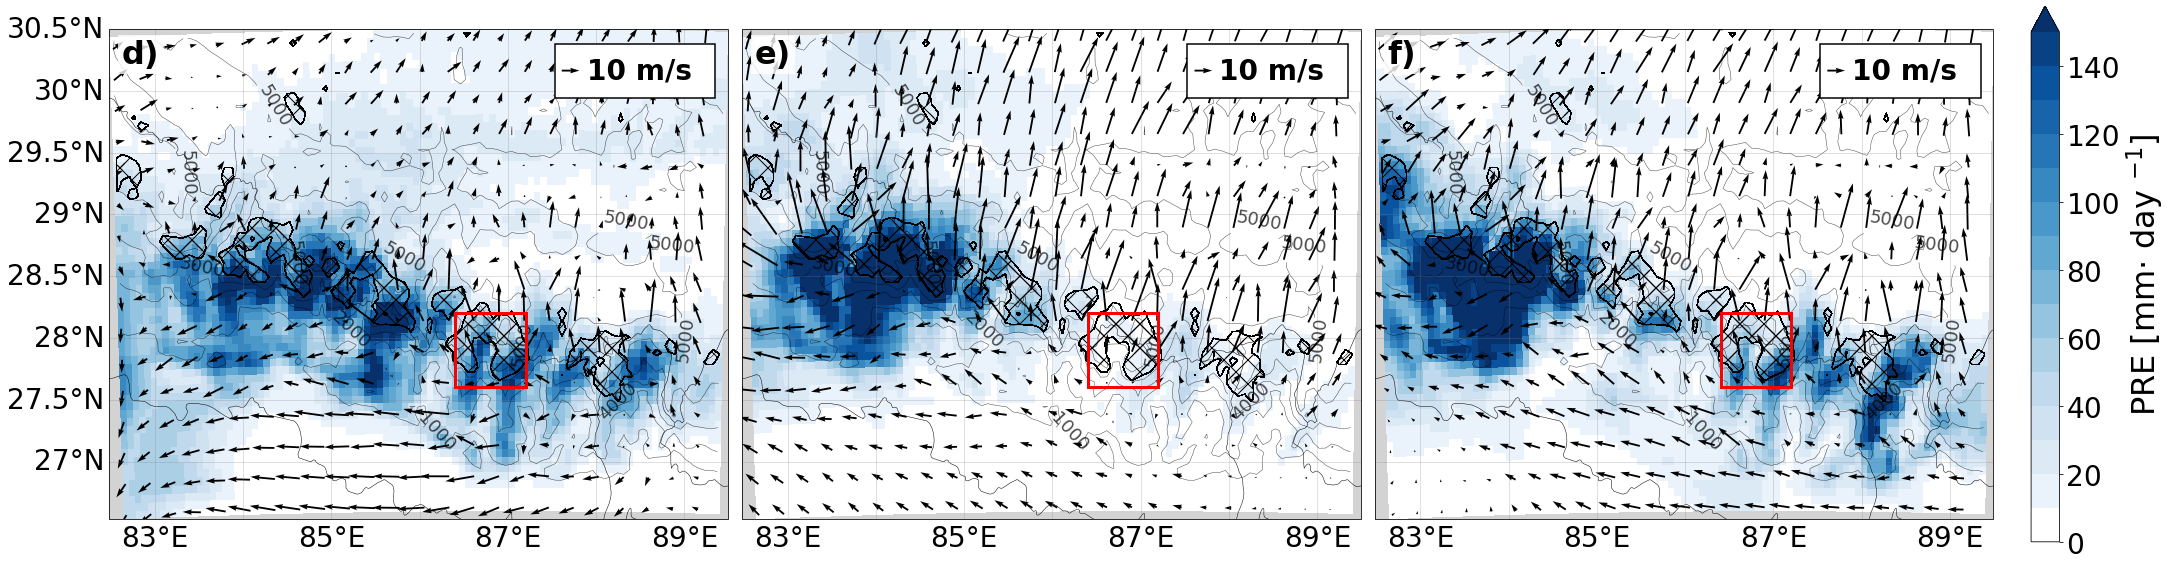

In [13]:
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.patches import Rectangle
import cartopy.crs as ccrs
import cartopy.feature as cfeature
fig, axs = plt.subplots(
    1, 3,
    figsize=(30, 10),
    subplot_kw={"projection": ccrs.PlateCarree()},
    constrained_layout=True
)

pre_list = [pre1_event, pre2_event, pre3_event]
u_list   = [u1_event, u2_event, u3_event]
v_list   = [v1_event, v2_event, v3_event]

years = [2013, 2014, 2021]
days  = [14, 14, 19]
letters = ["d", "e", "f"]

levels = np.arange(0, 160, 10)

cmap = plt.get_cmap("Blues").copy()
colors = cmap(np.linspace(0, 1, cmap.N))
colors[0] = [1, 1, 1, 1]
cmap_white0 = mcolors.ListedColormap(colors)

norm = mcolors.BoundaryNorm(levels, cmap_white0.N, extend="max")

skip = 4

for ax, pre_event, u_event, v_event, year, day, letter in zip(
        axs, pre_list, u_list, v_list, years, days, letters):
    
    u_event = u_event.where(u_event < 1e20)
    v_event = v_event.where(v_event < 1e20)

    ax.coastlines()
    ax.add_feature(cfeature.BORDERS, linewidth=0.5)
    ax.add_feature(cfeature.LAND, facecolor="lightgray")

    c = ax.pcolormesh(
        LONS,
        LATS,
        pre_event,
        cmap=cmap_white0,
        norm=norm,
        shading="auto",
        transform=ccrs.PlateCarree()
    )

    Q = ax.quiver(
        LONS[::skip, ::skip],
        LATS[::skip, ::skip],
        u_event[::skip, ::skip],
        v_event[::skip, ::skip],
        transform=ccrs.PlateCarree(),
        scale=350,
        width=0.003
    )

    qk = ax.quiverkey(
    Q,
    X=0.68+0.08,
    Y=0.895+0.02,
    U=10,
    label="10 m/s",
    labelpos="E",
    coordinates="axes",
    fontproperties={"size":28, "weight":"bold"}
    )
    qk.set_zorder(4)   
    ax.text(
    0.02, 0.98,
    f"{letter})",
    transform=ax.transAxes,
    fontsize=32,
    fontweight="bold",
    va="top",
    ha="left",
    bbox=dict(facecolor="white", edgecolor="none", alpha=0.8)
    )
    gl = ax.gridlines(draw_labels=True,
                      linewidth=0.5,
                      color="gray",
                      alpha=0.5)

    gl.top_labels = False
    gl.right_labels = False

    if ax != axs[0]:
        gl.left_labels = False

    gl.xlabel_style = {"size":28}
    gl.ylabel_style = {"size":28}

   # ax.set_title(
  ##      f"{year}-10-{day:02d}",
   #     fontsize=32,
   #     fontweight="bold",
   #     pad=18
   # )

    # Glacier mask
    ax.contourf(
        LONS,
        LATS,
        dsICE,
        levels=[10, 50, 100],
        hatches=["", "X", "X"],
        colors="none",
        transform=ccrs.PlateCarree()
    )

    SH1 = ax.contour(
        LONS,
        LATS,
        dsSH,
        levels=[1000,2000,3000,4000,5000,6000,7000],
        colors="k",
        linewidths=0.5,
        alpha=0.7,
        transform=ccrs.PlateCarree()
    )

    ax.clabel(SH1, inline=True, fontsize=18, fmt="%d")

    ICE2 = ax.contourf(
        LONS,
        LATS,
        dsICE,
        levels=[20,100],
        hatches=["X","X"],
        colors="none",
        transform=ccrs.PlateCarree(),
        zorder=4
    )

    for coll in ICE2.collections:
        coll.set_edgecolor("black")
        coll.set_linewidth(0.6)
        coll.set_facecolor("none")

    ax.add_patch(
        Rectangle(
    (0.64+0.08, 0.84+0.02),
    0.26,
    0.11,
    transform=ax.transAxes,
    facecolor="white",
    edgecolor="black",
    linewidth=1.5,
    zorder=3
    )
    )
    rect = Rectangle(
        (86.4, 27.6),
        87.2 - 86.4,
        28.2 - 27.6,
        linewidth=3,
        edgecolor='red',
        facecolor='none',
        transform=ccrs.PlateCarree(),
        zorder=10
    )

    ax.add_patch(rect)
    ax.tick_params(labelsize=28)
    ax.set_aspect(1.4)

# Shared vertical colorbar
cb = fig.colorbar(
    c,
    ax=axs,
    orientation="vertical",
    pad=0.02,
    shrink=0.75,
    aspect=18
)

cb.set_label("PRE [mm$\cdot$ day $^{-1}$]", fontsize=32)
cb.ax.tick_params(labelsize=28)

plotname = f"FIG11def_MAR_pre_uv{lev0}events_rect"

plt.savefig(
    f"{plotsDir}{plotname}.png",
    dpi=300,
    bbox_inches="tight"
)
print(plotname)
plt.show()

In [14]:
#t_event.plot()